# Лабораторна робота №3. Розпізнавання тексту з застосуванням ШІ

**Студент:** Скиданчук М.Д.  
**Варіант:** 6  
**Набір:** Perestoroha OCR · **Інструменти:** EasyOCR, PaddleOCR · **Чинник:** зниження роздільності

## 0. Налаштування і персональні параметри

In [2]:
import os, re, time, hashlib, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image, ImageDraw, ImageFont
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

# ---- персональні параметри ----
STUDENT = "Скиданчук М.Д."
VARIANT = 6
STUDENT_ID = 962
SEED = 1000 * VARIANT + STUDENT_ID   # 6962
rng = np.random.default_rng(SEED)

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def stamp(ax, title):
    """Заголовок графіка з персональним підписом студента."""
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

print(STUDENT, VARIANT, SEED)

Скиданчук М.Д. 6 6962


## 1. Гіпотези (записано до запуску розпізнавання, 07.11.2026)

Прогнози сформульовано до першого запуску EasyOCR і PaddleOCR на даних. Чернетку підготовлено разом з ШІ-асистентом, студент її розглянув і погодив; оцінка («підтверджено / спростовано») буде додана після експериментів.

| № | Гіпотеза (прогноз) | Обґрунтування | Оцінка |
|---|---|---|---|
| Г1 | На картках Perestoroha без зниження роздільності (×1) CER обох інструментів не менший за 0,60; PaddleOCR не буде кращим за EasyOCR. | Інструменти навчені на друкованому тексті, а картки рукописні зі старими літерами (ѣ, ъ, титла). | — |
| Г2 | При зниженні роздільності ×4 CER обох інструментів не менший за 0,90; найстрімкіше зростання між ×1 і ×2,5. Поріг 10% перевищується вже на ×1 (плато одразу високо). | При ×4 картка має ~290×188 пікселів, штрихи рукопису зливаються. | — |
| Г3 | Розширена нормалізація історичних графем (ѣ→і, ъ→∅, ѡ→о тощо, без титл і наголосів) знизить CER лише на 2–5 процентних пунктів. | Основна помилка пов'язана з рукописом, а не з окремими старими літерами. | — |
| Г4 | На фото меморіальної дошки / старого напису CER буде у 2–3 рази нижчим, ніж на картках Perestoroha. | Друкований або вирізаний текст ближчий до даних, на яких навчені моделі. | — |
| Г5 | На фото власної рукописної сторінки CER буде щонайменше у 10 разів вищим за CER на синтетичному друкованому тексті (його очікую ≤ 0,05 на ×1). | Рукопис, тіні й кут зйомки (domain gap). | — |
| Г6 | Бінаризація Оцу погіршить CER обох інструментів не менш ніж на 5 п.п.; збільшення ×2 з медіанним фільтром покращить результат. | Нейромережі навчені на зображеннях у відтінках сірого; бінаризація руйнує тонкі штрихи. | — |
| Г7 | На CPU PaddleOCR опрацьовує зображення швидше за EasyOCR (час ≤ 0,7 від часу EasyOCR). | Легший конвеєр детекції й розпізнавання. | — |


## 2. Відкритий набір Perestoroha OCR: огляд структури

In [3]:
from datasets import load_dataset

ds = load_dataset("lang-uk/perestoroha-ocr")
print(ds)                       # спліти, кількість записів, назви полів
for name, part in ds.items():
    print(name, part.features)


DatasetDict({
    train: Dataset({
        features: ['id', 'image', 'transcription', 'card_num_primary', 'card_num_secondary', 'card_num_tertiary', 'card_num_notes', 'source_city', 'source_date', 'source_reference', 'notes', 'reviewed_at'],
        num_rows: 278
    })
    validation: Dataset({
        features: ['id', 'image', 'transcription', 'card_num_primary', 'card_num_secondary', 'card_num_tertiary', 'card_num_notes', 'source_city', 'source_date', 'source_reference', 'notes', 'reviewed_at'],
        num_rows: 122
    })
    test: Dataset({
        features: ['id', 'image', 'transcription', 'card_num_primary', 'card_num_secondary', 'card_num_tertiary', 'card_num_notes', 'source_city', 'source_date', 'source_reference', 'notes', 'reviewed_at'],
        num_rows: 30
    })
})
train {'id': Value('string'), 'image': Image(mode=None, decode=True), 'transcription': Value('string'), 'card_num_primary': Value('string'), 'card_num_secondary': Value('string'), 'card_num_tertiary': Value('s

In [4]:
# перший запис: що лежить у кожному полі
split = list(ds.keys())[0]
sample = ds[split][0]
for k, v in sample.items():
    if hasattr(v, "size"):                     # зображення PIL
        print(k, "-> image", v.size, v.mode)
    else:
        print(k, "->", repr(v)[:300])
sample[[k for k, v in sample.items() if hasattr(v, "size")][0]].save("data/perestoroha_0.png")


id -> 'Auto-Color0002/182'
image -> image (1160, 752) RGB
transcription -> 'пан воєвода кієвскій для коней\r\nєго себѣ слалъ с килькома сты червоных\r\nЛьвів, 1605-1606, Перест. 38'
card_num_primary -> '10'
card_num_secondary -> None
card_num_tertiary -> '153'
card_num_notes -> '10 top-left in pencil (circled); 153 bottom-right in pencil'
source_city -> 'Львів'
source_date -> '1605-1606'
source_reference -> 'Перест. 38'
notes -> "Second line opens with 'ето' as written (likely scribe's form of 'єго'); 'сты' written with titlo-like horizontal bar above but treated as plain letters per preset rules."
reviewed_at -> '2026-05-06T18:54:16.666799+00:00'


## 3. Нормалізація тексту та метрики CER / WER

**Формули.** Відстань Левенштейна рахується за символами (CER) і за словами (WER):
CER = (S + D + I) / N, де S, D, I — заміни, видалення, вставлення, N — довжина еталону в символах (для WER — у словах).
CER може перевищувати 1, якщо інструмент вставив багато зайвого.

**Усереднення.** У роботі використовується *мікроусереднення* (сума помилок за всіма зразками, поділена на сумарну довжину еталонів), якщо не сказано інше; для окремих зразків CER рахується окремо.

**Правила нормалізації** (однакові для всіх інструментів і наборів):
1. Unicode NFC (літера «й», «ї» — один символ).
2. Усі апострофи (’ ʼ ` ´ ′ ‘) зводяться до `'`; усі види тире (– — ‒ ― −) до `-`; лапки („ “ ” « » ‟) до `"`.
3. Послідовності пробілів і переноси рядків замінюються одним пробілом.
4. Регістр і пунктуація **зберігаються** для синтетичних і відкритих даних (для пунктуації втрачається інформація, а еталон її має). Для власних фото рукопису, написаного великими літерами, порівняння **без урахування регістру** (`fold=True`) — зафіксоване рішення.
5. **Розширена нормалізація історичних графем** (`hist=True`, особливість варіанта 6): ѣ→і, ъ→∅, ѡ/ѻ/ѽ→о, ѧ/ѩ/ꙗ→я, ѫ/ѹ/ꙋ→у, ѥ→є, ѕ→з, ѵ→и, ѳ→ф, ѿ→от, ы→и, ѯ→кс, ѱ→пс; видалення комбінованих знаків (титла, наголоси) та дужок розкриття скорочень. Метрики з `hist=False` і `hist=True` порівнюються в розділі про особливість варіанта.

In [5]:
# ---- нормалізація ----
APOSTROPHES = "\u2019\u02bc`\u00b4\u2032\u2018"
DASHES = "\u2013\u2014\u2012\u2015\u2212"
QUOTES = "\u201e\u201c\u201d\u00ab\u00bb\u201f"

# історичні графеми -> сучасні (розширена нормалізація)
HIST_MAP = {
    "ѣ": "і", "Ѣ": "І", "ъ": "", "Ъ": "", "ѡ": "о", "Ѡ": "О", "ѻ": "о", "ѽ": "о",
    "ѧ": "я", "Ѧ": "Я", "ѩ": "я", "ꙗ": "я", "ѫ": "у", "ѹ": "у", "ꙋ": "у", "Ѹ": "У",
    "ѥ": "є", "ѕ": "з", "Ѕ": "З", "ѵ": "и", "Ѵ": "И", "ѳ": "ф", "Ѳ": "Ф",
    "ѿ": "от", "ы": "и", "Ы": "И", "ѯ": "кс", "ѱ": "пс",
}

def normalize(s, hist=False, fold=False):
    """Єдина нормалізація тексту перед обчисленням метрик."""
    s = unicodedata.normalize("NFC", s)
    for ch in APOSTROPHES:
        s = s.replace(ch, "'")
    for ch in DASHES:
        s = s.replace(ch, "-")
    for ch in QUOTES:
        s = s.replace(ch, '"')
    if hist:
        s = "".join(HIST_MAP.get(c, c) for c in s)
        # після NFC «й», «ї» є одним символом, тому видаляються лише титла, наголоси тощо
        s = "".join(c for c in s if unicodedata.category(c) != "Mn")
        s = re.sub(r"[()\[\]]", "", s)
    if fold:
        s = s.casefold()
    return re.sub(r"\s+", " ", s).strip()

# ---- метрики ----
def cer(gt, pred, **kw):
    g, p = normalize(gt, **kw), normalize(pred, **kw)
    return Levenshtein.distance(g, p) / max(len(g), 1)

def wer(gt, pred, **kw):
    g, p = normalize(gt, **kw).split(), normalize(pred, **kw).split()
    return Levenshtein.distance(g, p) / max(len(g), 1)

def cer_micro(pairs, **kw):
    """Мікроусереднений CER за списком пар (еталон, результат)."""
    errs = sum(Levenshtein.distance(normalize(g, **kw), normalize(p, **kw)) for g, p in pairs)
    total = sum(len(normalize(g, **kw)) for g, _ in pairs)
    return errs / max(total, 1)

def edit_ops(gt, pred, **kw):
    """Список операцій (op, символ еталону, символ результату): replace / delete / insert."""
    g, p = normalize(gt, **kw), normalize(pred, **kw)
    ops = []
    for tag, i1, i2, j1, j2 in Levenshtein.opcodes(g, p):
        if tag == "replace":
            ops += [("replace", g[i], p[j]) for i, j in zip(range(i1, i2), range(j1, j2))]
        elif tag == "delete":
            ops += [("delete", g[i], "") for i in range(i1, i2)]
        elif tag == "insert":
            ops += [("insert", "", p[j]) for j in range(j1, j2)]
    return ops

# ---- самоперевірка за прикладом з методички ----
assert abs(cer("інженерія даних", "інженерія даиих") - 1 / 15) < 1e-9     # CER = 1/15 ≈ 0,067
assert abs(wer("інженерія даних", "інженерія даиих") - 0.5) < 1e-9        # WER = 1/2
assert normalize("м’ята") == normalize("м'ята")                          # апострофи
assert normalize("рѣка ѿ", hist=True) == "ріка от"                       # історичні графеми
assert cer("Привіт", "ПРИВІТ", fold=True) == 0 and cer("Привіт", "ПРИВІТ") > 0
print("Перевірка метрик пройдена")

Перевірка метрик пройдена


## 4. Синтетичний набір з еталонною розміткою

Рядки вибираються з `corpus.txt` (Панас Мирний, «Хіба ревуть воли, як ясла повні?», остання цифра варіанта 6) за допомогою `numpy.random.default_rng([SEED, 1])`, тому набір повністю відтворюється за значенням SEED. Кожен рядок малюється окремим зображенням (чорний текст на білому тлі, шрифт і розмір вибираються за SEED). Еталон зберігається у `data/synthetic_gt.txt`, його хеш SHA-256 наводиться нижче й у звіті.

In [6]:
FONT_CANDIDATES = [
    # Windows
    "C:/Windows/Fonts/arial.ttf", "C:/Windows/Fonts/times.ttf", "C:/Windows/Fonts/calibri.ttf",
    "C:/Windows/Fonts/verdana.ttf", "C:/Windows/Fonts/tahoma.ttf",
    # Linux
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSerif.ttf",
    "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    "/usr/share/fonts/truetype/liberation/LiberationSerif-Regular.ttf",
    # macOS
    "/Library/Fonts/Arial.ttf",
]
FONTS = [p for p in FONT_CANDIDATES if os.path.exists(p)]
assert FONTS, "Не знайдено жодного шрифту з кирилицею: додайте шляхи до FONT_CANDIDATES"
print("Шрифти:", [os.path.basename(p) for p in FONTS])

N_LINES = 40
with open("corpus.txt", encoding="utf-8") as f:
    corpus = [s.strip() for s in f if 20 <= len(s.strip()) <= 70]
print("Рядків у корпусі після фільтра 20–70 символів:", len(corpus))

rng_text = np.random.default_rng([SEED, 1])
rng_font = np.random.default_rng([SEED, 2])
idx = np.sort(rng_text.choice(len(corpus), size=N_LINES, replace=False))
lines = [corpus[i] for i in idx]

with open("data/synthetic_gt.txt", "w", encoding="utf-8", newline="\n") as f:
    f.write("\n".join(lines) + "\n")
with open("data/synthetic_gt.txt", "rb") as f:
    GT_SHA256 = hashlib.sha256(f.read()).hexdigest()
print("SHA-256 еталону:", GT_SHA256)
print("Кількість рядків:", len(lines), "| SEED =", SEED)

Шрифти: ['arial.ttf', 'times.ttf', 'calibri.ttf', 'verdana.ttf', 'tahoma.ttf']
Рядків у корпусі після фільтра 20–70 символів: 71
SHA-256 еталону: 4700721d5f83d2229377e9ba61a7400ab4558f87f9a89856821f83908ab3a1bf
Кількість рядків: 40 | SEED = 6962


In [7]:
def render_line(text, font_path, size, pad=20):
    """Малює рядок тексту (чорний на білому) і повертає масив відтінків сірого."""
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

os.makedirs("data/synthetic", exist_ok=True)
synth = []   # (id, еталон, зображення, шрифт, розмір)
for i, text in enumerate(lines):
    font_path = FONTS[int(rng_font.integers(len(FONTS)))]
    size = int(rng_font.integers(28, 45))
    img = render_line(text, font_path, size)
    cv2.imwrite(f"data/synthetic/line_{i:02d}.png", img)
    synth.append({"id": f"line_{i:02d}", "gt": text, "img": img,
                  "font": os.path.basename(font_path), "size": size})

print("Створено зображень:", len(synth), "| приклад розміру:", synth[0]["img"].shape)

Створено зображень: 40 | приклад розміру: (75, 1005)


### 4.1 Чинник деградації: зниження роздільності

Реалізація (`degrade`) виконана самостійно: зображення зменшується в `factor` разів із усередненням за площею (`cv2.INTER_AREA`, як при зйомці камерою з меншою роздільністю), а потім білінійно повертається до початкових розмірів. Геометрія кадру зберігається, а дрібні деталі штрихів безповоротно втрачаються. Рівні: 1; 1,5; 2; 2,5; 3; 4 (рівень 1 — без змін).

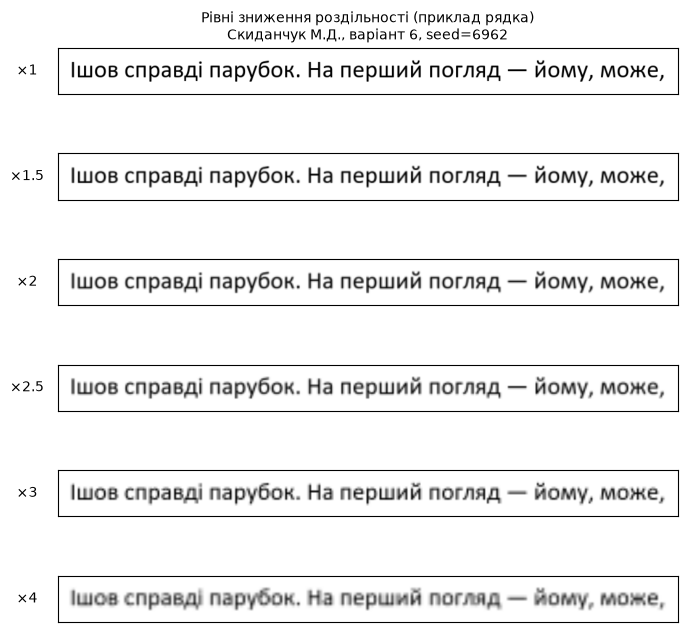

In [8]:
LEVELS = [1, 1.5, 2, 2.5, 3, 4]

def degrade(img, factor):
    """Зниження роздільності в `factor` разів із поверненням до початкового розміру."""
    if factor == 1:
        return img.copy()
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, round(w / factor)), max(1, round(h / factor))),
                       interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

# ілюстрація рівнів на одному рядку
fig, axes = plt.subplots(len(LEVELS), 1, figsize=(8, 1.2 * len(LEVELS) + 0.8))
for ax, lvl in zip(axes, LEVELS):
    ax.imshow(degrade(synth[0]["img"], lvl), cmap="gray", vmin=0, vmax=255)
    ax.set_ylabel(f"×{lvl}", rotation=0, labelpad=22, va="center")
    ax.set_xticks([]); ax.set_yticks([])
stamp(axes[0], "Рівні зниження роздільності (приклад рядка)")
fig.savefig("figures/fig0_degradation_levels.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Відкритий набір: вибір 30 карток Perestoroha

Набір містить цілі картки (сторінки), а не вирізані рядки, тому за методичкою достатньо 20 сторінок; беремо **30 карток**, випадково обраних з усіх 430 за допомогою `default_rng([SEED, 3])`. Ідентифікатори зберігаються у `data/perestoroha_ids.json`. Еталон картки — рядки поля `transcription`, з'єднані пробілом. Зображення (300 dpi, ~1160×752) переводяться у відтінки сірого.

In [ ]:
from datasets import load_dataset, concatenate_datasets
from collections import Counter
import json

ds_all = load_dataset("lang-uk/perestoroha-ocr")
full = concatenate_datasets([ds_all[s] for s in ds_all])      # train + validation + test = 430 карток
N_CARDS = 30
card_idx = np.sort(np.random.default_rng([SEED, 3]).choice(len(full), size=N_CARDS, replace=False))

cards = []
for i in card_idx:
    row = full[int(i)]
    gt = " ".join(l.strip() for l in row["transcription"].splitlines() if l.strip())
    gray = cv2.cvtColor(np.array(row["image"].convert("RGB")), cv2.COLOR_RGB2GRAY)
    cards.append({"id": row["id"], "gt": gt, "img": gray})

with open("data/perestoroha_ids.json", "w", encoding="utf-8") as f:
    json.dump([c["id"] for c in cards], f, ensure_ascii=False, indent=1)
print("Карток:", len(cards), "| розмір першої:", cards[0]["img"].shape)
print("Приклад еталону:", cards[0]["gt"])

In [ ]:
# Інвентар символів еталону: які символи лежать поза сучасним алфавітом
UK_ALPHABET = set("абвгґдеєжзиіїйклмнопрстуфхцчшщьюя")
counter = Counter("".join(c["gt"] for c in cards))
total_chars = sum(counter.values())
def is_modern(ch):
    return ch.lower() in UK_ALPHABET or (ch.isascii() and not ch.isalpha()) or ch == " "
outside = {ch: n for ch, n in counter.items() if not is_modern(ch) and not ch.isascii()}
OOA_SHARE = sum(outside.values()) / total_chars
print(f"Символів в еталоні: {total_chars}; поза сучасним алфавітом: {sum(outside.values())} ({OOA_SHARE:.1%})")
for ch, n in sorted(outside.items(), key=lambda kv: -kv[1])[:20]:
    print(repr(ch), f"U+{ord(ch):04X}", unicodedata.name(ch, "?"), n)

# приклади карток для звіту
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, c in zip(axes, cards[:3]):
    ax.imshow(c["img"], cmap="gray"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(c["gt"][:45] + "…", fontsize=7)
stamp(axes[1], "Приклади карток Perestoroha")
fig.savefig("figures/fig1_perestoroha_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Попередня обробка (абляційний набір конфігурацій)

Кроки: `upscale2` — збільшення вдвічі (бікубічна інтерполяція); `median` — медіанний фільтр 3×3; `clahe` — адаптивне вирівнювання контрасту; `otsu` — глобальна бінаризація Оцу; `adaptive` — адаптивна гаусова бінаризація. Шість конфігурацій абляційного експерименту (мінімум за методичкою — 4) перевіряють гіпотезу Г6.

In [ ]:
def preprocess(gray, steps):
    """Послідовне застосування кроків попередньої обробки до зображення у відтінках сірого."""
    out = gray
    for s in steps:
        if s == "upscale2":
            out = cv2.resize(out, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
        elif s == "median":
            out = cv2.medianBlur(out, 3)
        elif s == "clahe":
            out = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(out)
        elif s == "otsu":
            _, out = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        elif s == "adaptive":
            out = cv2.adaptiveThreshold(out, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, 31, 15)
        else:
            raise ValueError(f"Невідомий крок: {s}")
    return out

ABLATION = {
    "raw": (),
    "upscale2": ("upscale2",),
    "upscale2+median": ("upscale2", "median"),
    "clahe": ("clahe",),
    "otsu": ("otsu",),
    "adaptive": ("adaptive",),
}

# ілюстрація: одна картка після кожної конфігурації
fig, axes = plt.subplots(2, 3, figsize=(12, 5))
for ax, (name, steps) in zip(axes.ravel(), ABLATION.items()):
    ax.imshow(preprocess(cards[0]["img"], steps), cmap="gray")
    ax.set_title(name, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Попередня обробка: конфігурації абляції\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig2_preprocessing_configs.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Інструменти розпізнавання: EasyOCR і PaddleOCR

Обидва інструменти повертають області тексту з оцінкою впевненості. Для сторінкового розпізнавання фрагменти групуються в рядки за вертикальним положенням (поріг — 0,6 медіанної висоти фрагмента), всередині рядка впорядковуються зліва направо та з'єднуються пробілом. Впевненість сторінки — середнє значення за фрагментами. Час вимірюється `time.perf_counter()`.

In [ ]:
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"   # не перевіряти доступність джерел моделей
import easyocr
from paddleocr import PaddleOCR

reader = easyocr.Reader(["uk", "en"], gpu=False)

def make_paddle():
    last = None
    for lang in ("uk", "east_slavic"):
        try:
            ocr = PaddleOCR(lang=lang, use_doc_orientation_classify=False,
                            use_doc_unwarping=False, use_textline_orientation=False)
            print("PaddleOCR: lang =", lang)
            return ocr
        except Exception as e:                       # noqa: BLE001
            last = e
            print("PaddleOCR lang", lang, "->", repr(e)[:200])
    raise last

paddle_ocr = make_paddle()

def join_items(items):
    """items: список (cx, cy, h, text, conf) -> (текст сторінки, середня впевненість)."""
    if not items:
        return "", 0.0
    h_med = float(np.median([it[2] for it in items]))
    items = sorted(items, key=lambda it: it[1])
    rows, cur = [], [items[0]]
    for it in items[1:]:
        if abs(it[1] - np.mean([c[1] for c in cur])) < 0.6 * h_med:
            cur.append(it)
        else:
            rows.append(cur); cur = [it]
    rows.append(cur)
    text = " ".join(" ".join(t[3] for t in sorted(r, key=lambda t: t[0])) for r in rows)
    return text, float(np.mean([it[4] for it in items]))

def ocr_easyocr(img):
    t0 = time.perf_counter()
    res = reader.readtext(img)
    items = [(np.mean([p[0] for p in b]), np.mean([p[1] for p in b]),
              max(p[1] for p in b) - min(p[1] for p in b), t, float(c)) for b, t, c in res]
    text, conf = join_items(items)
    return text, conf, time.perf_counter() - t0

def ocr_paddle(img):
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    t0 = time.perf_counter()
    items = []
    for r in paddle_ocr.predict(img):
        polys = r["rec_polys"] if "rec_polys" in r else r["dt_polys"]
        for t, s, p in zip(r["rec_texts"], r["rec_scores"], polys):
            p = np.asarray(p)
            items.append((p[:, 0].mean(), p[:, 1].mean(), p[:, 1].max() - p[:, 1].min(), t, float(s)))
    text, conf = join_items(items)
    return text, conf, time.perf_counter() - t0

ENGINES = {"EasyOCR": ocr_easyocr, "PaddleOCR": ocr_paddle}

In [ ]:
# ---- димовий тест: по одному зображенню кожної групи ----
import paddle
print("easyocr", easyocr.__version__, "| paddleocr", __import__("paddleocr").__version__, "| paddle", paddle.__version__)

def load_own_gray(path, long_side=2000):
    gray = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2GRAY)
    k = long_side / max(gray.shape)
    return cv2.resize(gray, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)

with open("my_photos/page01_diffuse.txt", encoding="utf-8") as f:
    own_gt = f.read()
tests = {
    "синтетика": (synth[0]["img"], synth[0]["gt"]),
    "Perestoroha": (cards[0]["img"], cards[0]["gt"]),
    "власна сторінка": (load_own_gray("my_photos/page01_diffuse.jpg"), own_gt),
}
for gname, (img, gt) in tests.items():
    for ename, fn in ENGINES.items():
        text, conf, sec = fn(img)
        print(f"[{gname} | {ename}] CER={cer(gt, text):.3f} conf={conf:.2f} {sec:.1f} c")
        print("   еталон:", gt[:90].replace(chr(10), " "))
        print("   вихід :", text[:90])